# 01 · Exploration and cleaning

**Question for the project:** which treaties are unprofitable, and what explains it?
**This notebook:** load the two tables, clean the problems in them (writing down every decision), and look at the portfolio
before modelling anything. It ends with the hypotheses that notebook 02 tests.

*All data is synthetic, produced by `generate_data.py`. No client data is used.*

Loss ratio = claims paid ÷ premium earned. Above 1.0 the treaty paid out more than it took in.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Works whether the notebook is run from the repo root or from inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

## 1. Load

In [2]:
treaties = pd.read_csv(DATA / "treaties.csv")
treaty_year = pd.read_csv(DATA / "treaty_year.csv")
print("treaties:   ", treaties.shape)
print("treaty_year:", treaty_year.shape)
treaty_year.head()

treaties:    (155, 9)
treaty_year: (1167, 9)


,treaty_id,year,premium_earned,claims_paid,claim_count,large_claim_count,policies_in_force,avg_sum_insured,expense_amount
0,TR0001,2016,"4,090,410.290","2,783,823.610",35,0,7008,"84,676.920","395,771.530"
1,TR0001,2017,"4,227,284.990","5,837,051.110",66,0,6934,"86,793.840","284,797.180"
2,TR0001,2018,"4,395,975.750","4,588,790.000",48,1,6993,"88,963.690","433,903.320"
3,TR0001,2019,"4,038,209.770","3,402,063.650",38,0,6568,"91,187.780","289,006.940"
4,TR0001,2020,"4,176,802.890","2,648,377.760",20,0,6416,"93,467.480","270,487.470"


## 2. Clean

The generator planted four problems. For each one: what I found, and what I did. Nothing is fixed silently.

### 2a. Duplicated rows

In [3]:
dupes = treaty_year[treaty_year.duplicated(keep=False)]
n_dupes = int(treaty_year.duplicated().sum())
print(f"Fully duplicated rows: {n_dupes}")
print(f"Duplicated treaty-year keys: {treaty_year.duplicated(['treaty_id', 'year']).sum()}")
dupes

Fully duplicated rows: 1
Duplicated treaty-year keys: 1


,treaty_id,year,premium_earned,claims_paid,claim_count,large_claim_count,policies_in_force,avg_sum_insured,expense_amount
59,TR0007,2021,"564,348.790","302,429.750",3,1,2252,"488,458.800","37,190.190"
1002,TR0007,2021,"564,348.790","302,429.750",3,1,2252,"488,458.800","37,190.190"


In [4]:
treaty_year = treaty_year.drop_duplicates().reset_index(drop=True)
assert not treaty_year.duplicated(["treaty_id", "year"]).any()
print("Rows after removing the duplicate:", len(treaty_year))

Rows after removing the duplicate: 1166


**Found:** one treaty-year (TR0007, 2021) appears twice, identical in every column.
**Did:** kept one copy. An exact copy carries no new information and would double-count that year's premium and claims.

### 2b. Inconsistent cedent names

In [5]:
print("Distinct cedent_name values as stored:", treaties.cedent_name.nunique())
print(treaties.cedent_name.drop_duplicates().map(repr).head(10).to_string(index=False))

Distinct cedent_name values as stored: 57
     'Kookaburra Life   '
            'Mallee Life'
      'Bluegum Assurance'
    'Harbourview Life   '
       'Harbourview Life'
       'pelican bay life'
   'Cape Otway Assurance'
'Silver Wattle Insurance'
         'Jacaranda Life'
      'Harbourview  Life'


In [6]:
raw_names = treaties.cedent_name.copy()
treaties["cedent_name"] = (treaties.cedent_name
                           .str.strip()                        # leading / trailing spaces
                           .str.split().str.join(" ")          # repeated inner spaces
                           .str.title())                       # one casing
n_renamed = int((raw_names != treaties.cedent_name).sum())
print("Distinct cedent names after cleaning:", treaties.cedent_name.nunique())
print("Treaties whose cedent name was changed:", n_renamed)
treaties.cedent_name.value_counts().head()

Distinct cedent names after cleaning: 18
Treaties whose cedent name was changed: 50


cedent_name
Harbourview Life           14
Mallee Life                11
Jacaranda Life             11
Silver Wattle Insurance    11
Granite Belt Mutual        11
Name: count, dtype: int64

**Found:** 57 spellings of what are really 18 cedents (upper case, lower case, stray and doubled spaces).
**Did:** trimmed, collapsed inner spaces and standardised to title case. Without this, any group-by on cedent would split one
company into several.

### 2c. Join the tables and derive the target

In [7]:
rows_before = len(treaty_year)
df = treaty_year.merge(treaties, on="treaty_id", how="left", validate="many_to_one")
assert len(df) == rows_before, "the merge changed the row count"
assert df.line_of_business.notna().all(), "some treaty-years have no matching treaty"

df["loss_ratio"] = df.claims_paid / df.premium_earned
df["treaty_age"] = df.year - df.inception_year
print(f"{rows_before} rows before the merge, {len(df)} after: every treaty-year found its treaty.")

1166 rows before the merge, 1166 after: every treaty-year found its treaty.


`validate="many_to_one"` makes pandas raise an error if a treaty appeared twice in `treaties.csv`, and the row-count check
catches a merge that silently drops or multiplies rows. Loss ratio is computed here, not stored in the data.

### 2d. Impossible loss ratios

In [8]:
impossible = df[df.loss_ratio > 3.0]
n_impossible = len(impossible)
display(impossible[["treaty_id", "year", "premium_earned", "claims_paid", "loss_ratio"]])

# How does each of these compare with the same treaty's other years?
for tid in impossible.treaty_id:
    other = df[(df.treaty_id == tid) & (df.loss_ratio <= 3.0)].loss_ratio
    bad = impossible.loc[impossible.treaty_id == tid, "loss_ratio"].iloc[0]
    print(f"{tid}: suspicious year {bad:.2f} vs median of its other years {other.median():.2f} "
          f"(ratio {bad / other.median():.1f}x)")

,treaty_id,year,premium_earned,claims_paid,loss_ratio
761,TR0102,2021,"7,478,150.100","51,620,268.900",6.903
766,TR0103,2016,"5,375,655.190","36,620,085.700",6.812
1006,TR0133,2019,"14,281,161.510","103,335,337.700",7.236


TR0102: suspicious year 6.90 vs median of its other years 0.60 (ratio 11.6x)
TR0103: suspicious year 6.81 vs median of its other years 0.78 (ratio 8.7x)
TR0133: suspicious year 7.24 vs median of its other years 0.90 (ratio 8.1x)


In [9]:
df = df[df.loss_ratio <= 3.0].reset_index(drop=True)
print("Rows after removing impossible ratios:", len(df))

Rows after removing impossible ratios: 1163


**Found:** three treaty-years with loss ratios of 6.8 to 7.2, each roughly ten times that treaty's usual level. A
reinsurer paying out seven times its premium in one year, with normal years either side, is not plausible; it looks like
claims keyed with an extra zero.

**Did:** dropped the three rows (0.3% of the data). Dividing by ten would probably restore the right value, but that is a
guess about the cause; dropping costs almost nothing and assumes nothing. Kept as a limitation: if the source system
really had such years, the model would understate tail risk.

### 2e. Missing average sum insured

In [10]:
missing = df.avg_sum_insured.isna()
n_missing = int(missing.sum())
print(f"Missing avg_sum_insured: {missing.sum()} rows ({missing.mean():.1%})")
print(df[missing].line_of_business.value_counts().to_string())

Missing avg_sum_insured: 30 rows (2.6%)
line_of_business
Trauma               10
TPD                   7
Death                 7
Income Protection     6


In [11]:
df = df.sort_values(["treaty_id", "year"]).reset_index(drop=True)
df["avg_sum_insured_imputed"] = df.avg_sum_insured.isna()     # remember which values get filled
df["avg_sum_insured"] = (df.groupby("treaty_id").avg_sum_insured
                           .transform(lambda s: s.interpolate(limit_direction="both")))
print("Still missing after interpolation:", df.avg_sum_insured.isna().sum())

Still missing after interpolation: 0


**Found:** 30 rows (2.6%) without an average sum insured, spread across lines and years with no obvious pattern.
**Did:** filled each gap from the same treaty's neighbouring years (sum insured moves slowly year to year) and kept a flag
column `avg_sum_insured_imputed` so the filled values can always be identified. The field is not used in the regression,
so this choice cannot move the main results.

### 2f. Cleaning log

In [12]:
cleaning_log = pd.DataFrame([
    ("Duplicated treaty-year row", n_dupes, "Dropped the exact copy"),
    ("Inconsistent cedent_name spelling", n_renamed, "Trimmed, collapsed spaces, title case (treaties renamed)"),
    ("Loss ratio above 3.0 (claims keyed x10)", n_impossible, "Dropped as physically implausible"),
    ("Missing avg_sum_insured", n_missing, "Interpolated within treaty, flagged"),
], columns=["Problem", "Rows affected", "Decision"])
display(cleaning_log)

df.to_csv(DATA / "treaty_year_clean.csv", index=False)
print(f"Saved {len(df)} clean rows to data/treaty_year_clean.csv (used by notebooks 02 and 03)")

,Problem,Rows affected,Decision
0,Duplicated treaty-year row,1,Dropped the exact copy
1,Inconsistent cedent_name spelling,50,"Trimmed, collapsed spaces, title case (treatie..."
2,Loss ratio above 3.0 (claims keyed x10),3,Dropped as physically implausible
3,Missing avg_sum_insured,30,"Interpolated within treaty, flagged"


Saved 1163 clean rows to data/treaty_year_clean.csv (used by notebooks 02 and 03)


## 3. Look at the portfolio

Seven views, in order from the whole book down to individual drivers. Every figure is saved to `outputs/figures/`.

### Figure 1 · How much of the book is underwater?

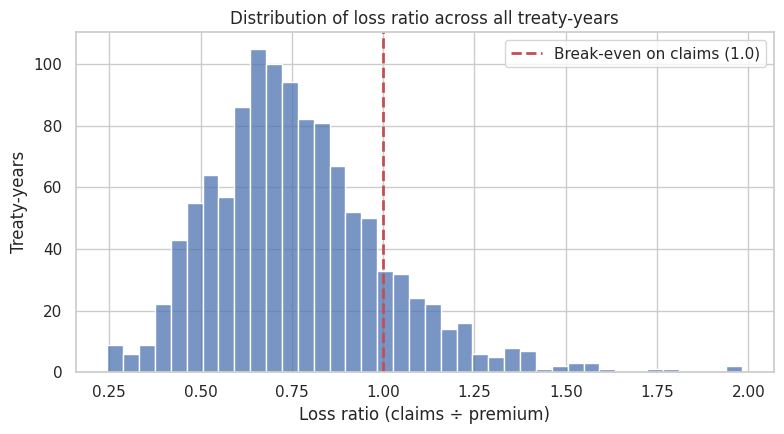

Mean 0.763, median 0.732
Treaty-years above 1.0: 169 of 1163 (14.5%)


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df.loss_ratio, bins=40, ax=ax, color="#4C72B0")
ax.axvline(1.0, color="#C44E52", linestyle="--", linewidth=2, label="Break-even on claims (1.0)")
ax.set(xlabel="Loss ratio (claims ÷ premium)", ylabel="Treaty-years",
       title="Distribution of loss ratio across all treaty-years")
ax.legend()
save_fig("01_loss_ratio_distribution")

print(f"Mean {df.loss_ratio.mean():.3f}, median {df.loss_ratio.median():.3f}")
print(f"Treaty-years above 1.0: {(df.loss_ratio > 1).sum()} of {len(df)} ({(df.loss_ratio > 1).mean():.1%})")

The typical treaty-year pays out about 73 cents in claims per dollar of premium (median 0.73), but the right tail is long:
**14.5% of treaty-years lost money on claims alone**, before commission and expenses. The skew matters later: a few very bad
years pull the mean (0.76) above the median.

### Figure 2 · Is it getting worse?

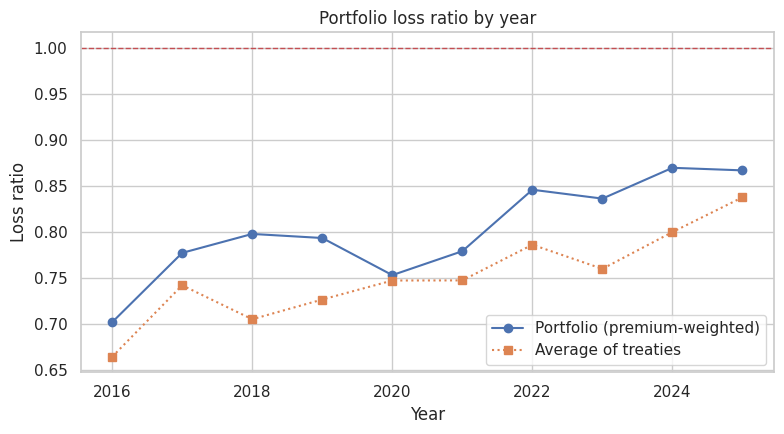

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
portfolio_lr,0.702,0.777,0.798,0.793,0.753,0.779,0.846,0.836,0.869,0.867
simple_mean,0.664,0.742,0.705,0.726,0.747,0.747,0.786,0.760,0.800,0.837


In [14]:
by_year = df.groupby("year").agg(premium=("premium_earned", "sum"), claims=("claims_paid", "sum"),
                                 simple_mean=("loss_ratio", "mean"))
by_year["portfolio_lr"] = by_year.claims / by_year.premium      # premium-weighted

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_year.index, by_year.portfolio_lr, marker="o", label="Portfolio (premium-weighted)")
ax.plot(by_year.index, by_year.simple_mean, marker="s", linestyle=":", label="Average of treaties")
ax.axhline(1.0, color="#C44E52", linestyle="--", linewidth=1)
ax.set(xlabel="Year", ylabel="Loss ratio", title="Portfolio loss ratio by year")
ax.legend()
save_fig("02_loss_ratio_by_year")
by_year[["portfolio_lr", "simple_mean"]].T

Yes. The premium-weighted loss ratio rises from about 0.70 in 2016 to about 0.87 by 2025, and the simple average of
treaties climbs from 0.66 to 0.84. Both lines move together, so it is not one large treaty dragging the average. Because the same treaties are getting older over these years, this is
the first hint that **treaty age** matters (tested in Figure 5 and notebook 02).

### Figure 3 · Loss ratio by line of business

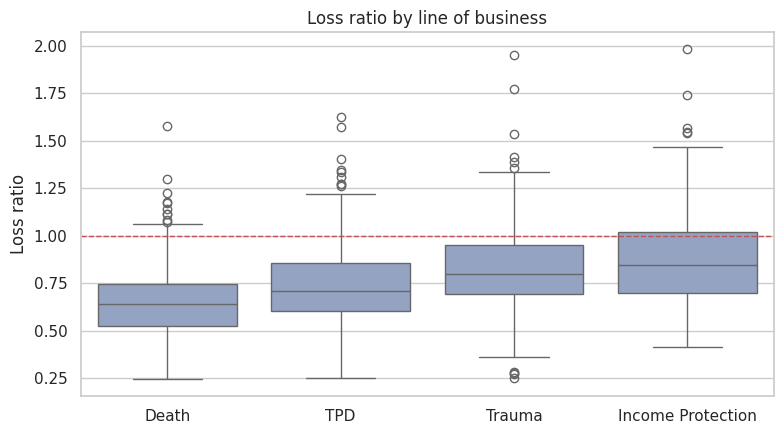

,count,median,mean,share_above_1
line_of_business,,,,
Death,390,0.639,0.654,0.049
TPD,212,0.712,0.745,0.137
Trauma,285,0.800,0.821,0.172
Income Protection,276,0.846,0.873,0.261


In [15]:
order = df.groupby("line_of_business").loss_ratio.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="line_of_business", y="loss_ratio", order=order, ax=ax, color="#8DA0CB")
ax.axhline(1.0, color="#C44E52", linestyle="--", linewidth=1)
ax.set(xlabel="", ylabel="Loss ratio", title="Loss ratio by line of business")
save_fig("03_loss_ratio_by_line")
df.groupby("line_of_business").loss_ratio.agg(["count", "median", "mean", lambda s: (s > 1).mean()]) \
  .rename(columns={"<lambda_0>": "share_above_1"}).loc[order]

**This is the biggest signal.** Death cover is comfortably profitable (median 0.64); Income Protection is the worst
(median 0.85) with about a quarter of its treaty-years above 1.0, and Trauma is close behind. This mirrors the Australian
market, where Income Protection was loss-making for years.

### Figure 4 · Loss ratio by treaty type

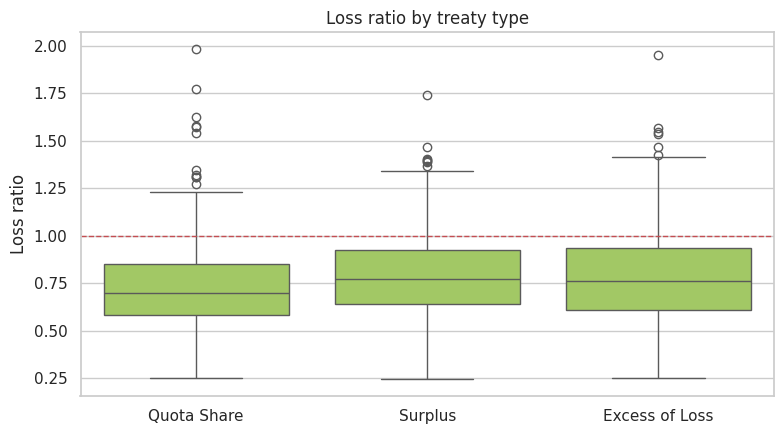

,count,median,std
treaty_type,,,
Quota Share,591,0.701,0.225
Surplus,354,0.774,0.226
Excess of Loss,218,0.764,0.273


In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="treaty_type", y="loss_ratio", ax=ax, color="#A6D854",
            order=["Quota Share", "Surplus", "Excess of Loss"])
ax.axhline(1.0, color="#C44E52", linestyle="--", linewidth=1)
ax.set(xlabel="", ylabel="Loss ratio", title="Loss ratio by treaty type")
save_fig("04_loss_ratio_by_type")
df.groupby("treaty_type").loss_ratio.agg(["count", "median", "std"]) \
  .loc[["Quota Share", "Surplus", "Excess of Loss"]]

Quota Share runs best (median 0.70); Surplus and Excess of Loss are a little worse (medians 0.76-0.77). The more useful
difference is the **spread**: Excess of Loss has the widest box and the highest standard deviation (0.27), which fits how it
works. It only pays when claims exceed a threshold, so results are lumpier year to year.

### Figure 5 · Loss ratio against treaty age

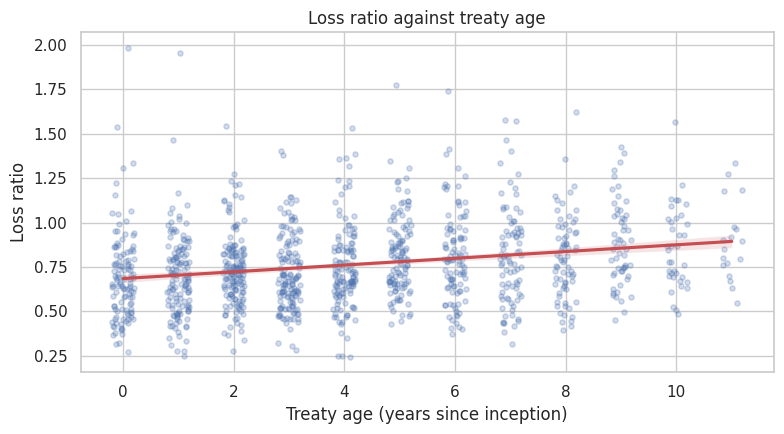

Simple trend: +0.019 loss ratio per extra year of age (correlation 0.23)


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=df, x="treaty_age", y="loss_ratio", ax=ax, x_jitter=0.2,
            scatter_kws={"alpha": 0.25, "s": 14}, line_kws={"color": "#C44E52"})
ax.set(xlabel="Treaty age (years since inception)", ylabel="Loss ratio", title="Loss ratio against treaty age")
save_fig("05_loss_ratio_vs_age")

slope, intercept = np.polyfit(df.treaty_age, df.loss_ratio, 1)
print(f"Simple trend: +{slope:.3f} loss ratio per extra year of age (correlation {df[['treaty_age', 'loss_ratio']].corr().iloc[0, 1]:.2f})")

Older treaties run worse: roughly **+0.02 per year** on a simple trend line. The cloud is wide, so age is far from the
whole story, but the direction is clear. The likely mechanism is anti-selection: healthy policyholders lapse over time
and the ones who stay claim more. This is a raw relationship; notebook 02 checks it holds after controlling for line of
business and the rest.

### Figure 6 · Loss ratio against treaty size

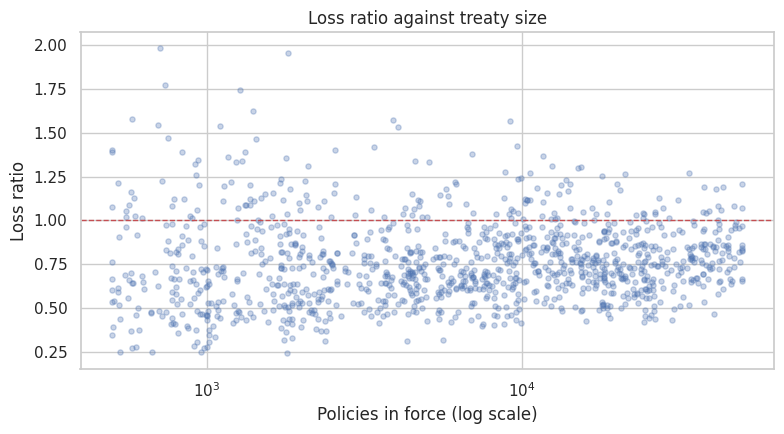

policies_in_force,Smallest 20%,2,3,4,Largest 20%
mean,0.762,0.725,0.747,0.803,0.780
std,0.328,0.245,0.211,0.194,0.170


In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df.policies_in_force, df.loss_ratio, alpha=0.3, s=14)
ax.set_xscale("log")
ax.axhline(1.0, color="#C44E52", linestyle="--", linewidth=1)
ax.set(xlabel="Policies in force (log scale)", ylabel="Loss ratio", title="Loss ratio against treaty size")
save_fig("06_loss_ratio_vs_size")

size_band = pd.qcut(df.policies_in_force, 5, labels=["Smallest 20%", "2", "3", "4", "Largest 20%"])
df.groupby(size_band, observed=True).loss_ratio.agg(["mean", "std"]).T

The funnel shape is the law of large numbers. Small treaties swing wildly (standard deviation about 0.33 in the smallest
fifth) while the largest cluster tightly (about 0.17), yet the **average barely changes with size** (0.73-0.80). Size
reduces volatility, not the average. Two consequences: one bad year on a small treaty is weak evidence, and the funnel
warns that the regression's errors will not have constant variance (checked in notebook 02).

### Figure 7 · Correlations between numeric columns

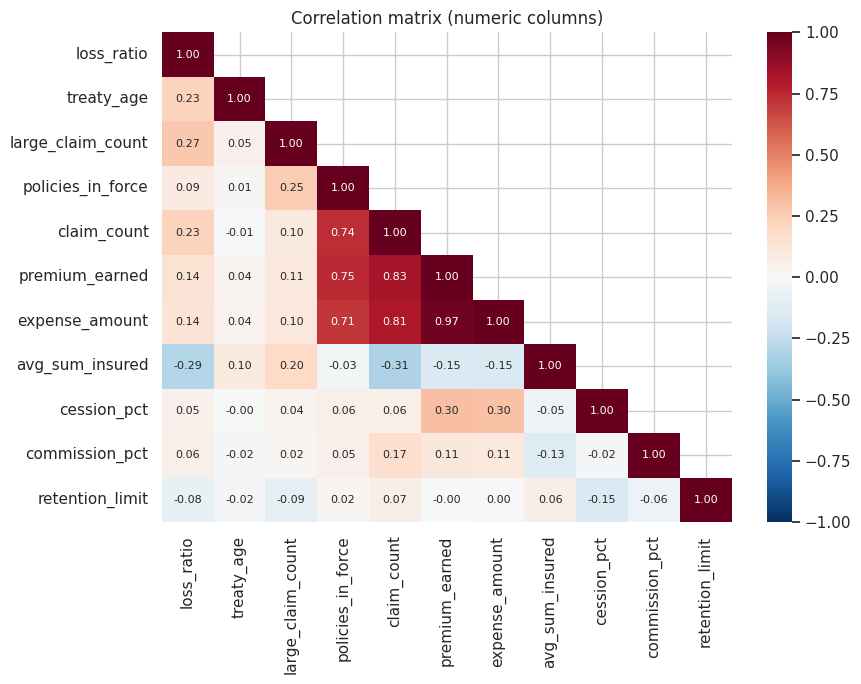

large_claim_count    0.270
claim_count          0.230
treaty_age           0.230
premium_earned       0.140
expense_amount       0.140
policies_in_force    0.090
commission_pct       0.060
cession_pct          0.050
retention_limit     -0.080
avg_sum_insured     -0.290
Name: loss_ratio, dtype: float64

In [19]:
numeric = ["loss_ratio", "treaty_age", "large_claim_count", "policies_in_force", "claim_count", "premium_earned",
           "expense_amount", "avg_sum_insured", "cession_pct", "commission_pct", "retention_limit"]
corr = df[numeric].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Correlation matrix (numeric columns)")
save_fig("07_correlation_heatmap")
corr["loss_ratio"].drop("loss_ratio").sort_values(ascending=False).round(2)

- Loss ratio's strongest numeric partners are **large claim count (0.27)** and **treaty age (0.23)**.
- **cession_pct is close to zero (0.05).** As expected: it scales premium and claims together, so it should cancel out.
- avg_sum_insured shows −0.29, but that is a **line-of-business effect in disguise**: Income Protection insures small
  annual benefits and has the worst ratios. It is not a driver in its own right.
- Multicollinearity warning: policies in force, claim count, premium and expenses are all strongly correlated (0.7 to 0.97);
  they all measure treaty size. The regression should include **only one** of them, log(policies in force).

## 4. What I now believe (hypotheses for notebook 02)

1. **Line of business is the main driver.** Income Protection and Trauma run materially worse than Death.
2. **Older treaties run worse**, by roughly 0.02 per year, even after allowing for line of business.
3. **Large claims drive individual bad years.** Each one should add a visible amount to that year's ratio.
4. **Size changes volatility, not the average.** log(policies in force) should be weak on the mean, and the residuals
   should fan out for small treaties.
5. **cession_pct and region should have no effect.** If the model finds them significant, something is wrong.